In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("ramen-ratings.csv")
df.head()

,Review #,Brand,Variety,Style,Country,Stars,Top Ten
0,2580,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75,NaN
1,2579,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1,NaN
2,2578,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25,NaN
3,2577,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75,NaN
4,2576,Ching's Secret,Singapore Curry,Pack,India,3.75,NaN


In [3]:
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (2580, 7)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2580 entries, 0 to 2579
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Review #  2580 non-null   int64
 1   Brand     2580 non-null   str  
 2   Variety   2580 non-null   str  
 3   Style     2578 non-null   str  
 4   Country   2580 non-null   str  
 5   Stars     2580 non-null   str  
 6   Top Ten   41 non-null     str  
dtypes: int64(1), str(6)
memory usage: 141.2 KB


In [5]:
df.describe(include="all")

,Review #,Brand,Variety,Style,Country,Stars,Top Ten
count,2580.000000,2580,2580,2578,2580,2580,41
unique,NaN,355,2413,7,38,51,38
top,NaN,Nissin,Beef,Pack,Japan,4,\n
freq,NaN,381,7,1531,352,384,4
mean,1290.500000,NaN,NaN,NaN,NaN,NaN,NaN
std,744.926171,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,645.750000,NaN,NaN,NaN,NaN,NaN,NaN
50%,1290.500000,NaN,NaN,NaN,NaN,NaN,NaN
75%,1935.250000,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
missing_values = df.isnull().sum()

print("Jumlah missing value:")
print(missing_values[missing_values > 0])

Jumlah missing value:
Style         2
Top Ten    2539
dtype: int64


In [7]:
#mengubah stars menjadi numerik
df["Stars"] = pd.to_numeric(df["Stars"], errors="coerce")

print("Missing value pada Stars setelah konversi:")
print(df["Stars"].isnull().sum())

#menghapus data yang starsnya tidak memiliki rating
df = df.dropna(subset=["Stars"])

print("Ukuran dataset setelah membersihkan Stars:")
print(df.shape)

Missing value pada Stars setelah konversi:
3
Ukuran dataset setelah membersihkan Stars:
(2577, 7)


In [8]:
df["Style"] = df["Style"].fillna(df["Style"].mode()[0])
df = df.drop(columns=["Review #", "Top Ten"])
df.head()

,Brand,Variety,Style,Country,Stars
0,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75
1,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1.00
2,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25
3,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75
4,Ching's Secret,Singapore Curry,Pack,India,3.75


In [9]:
missing_values = df.isnull().sum()

print("Missing value setelah cleaning:")
print(missing_values[missing_values > 0])

Missing value setelah cleaning:
Series([], dtype: int64)


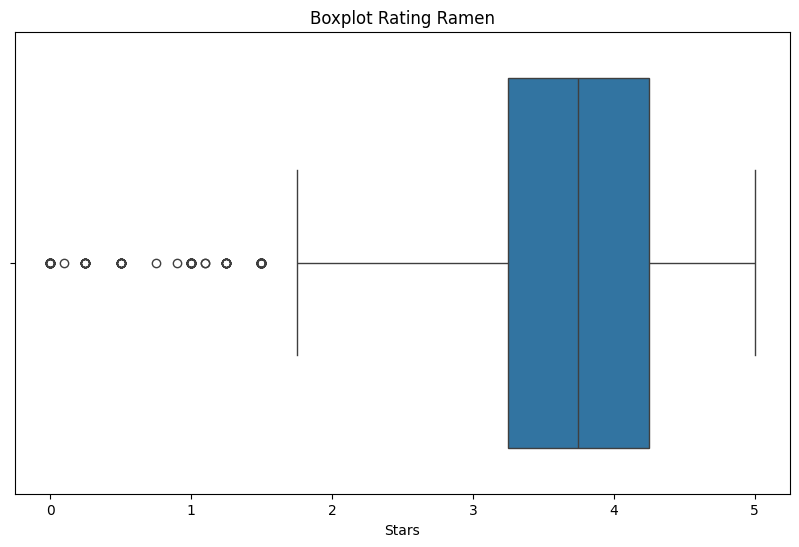

In [10]:
plt.figure(figsize=(10, 6))

sns.boxplot(x=df["Stars"])

plt.title("Boxplot Rating Ramen")
plt.xlabel("Stars")
plt.show()

In [11]:
Q1 = df["Stars"].quantile(0.25)
Q3 = df["Stars"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Stars"] < lower_bound) |
    (df["Stars"] > upper_bound)
]

print("Jumlah outlier:", len(outliers))

Jumlah outlier: 129


In [12]:
duplicates = df.duplicated()

print("Jumlah baris duplikat:", duplicates.sum())

df = df.drop_duplicates()

print("Ukuran dataset setelah menghapus duplicate:")
print(df.shape)

Jumlah baris duplikat: 5
Ukuran dataset setelah menghapus duplicate:
(2572, 5)


In [13]:
df["Stars"].describe()

count    2572.000000
mean        3.652935
std         1.015252
min         0.000000
25%         3.250000
50%         3.750000
75%         4.250000
max         5.000000
Name: Stars, dtype: float64

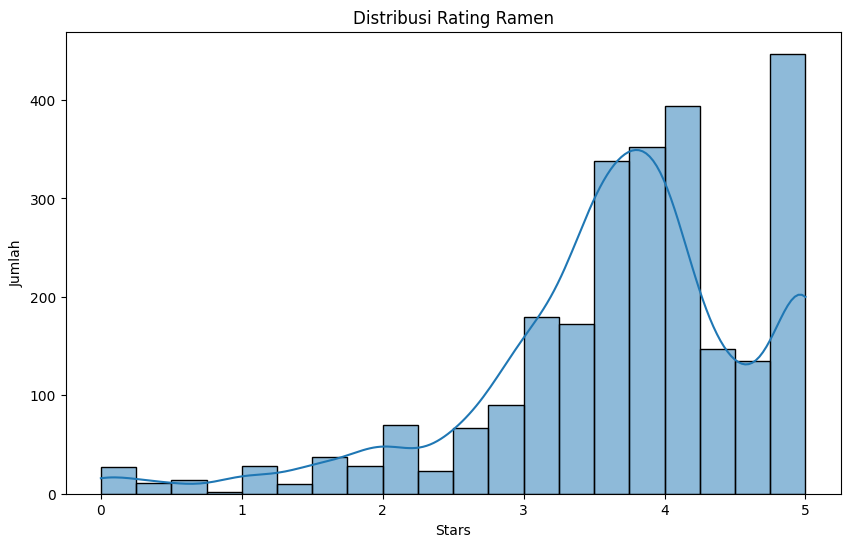

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(df["Stars"], bins=20, kde=True)

plt.title("Distribusi Rating Ramen")
plt.xlabel("Stars")
plt.ylabel("Jumlah")
plt.show()

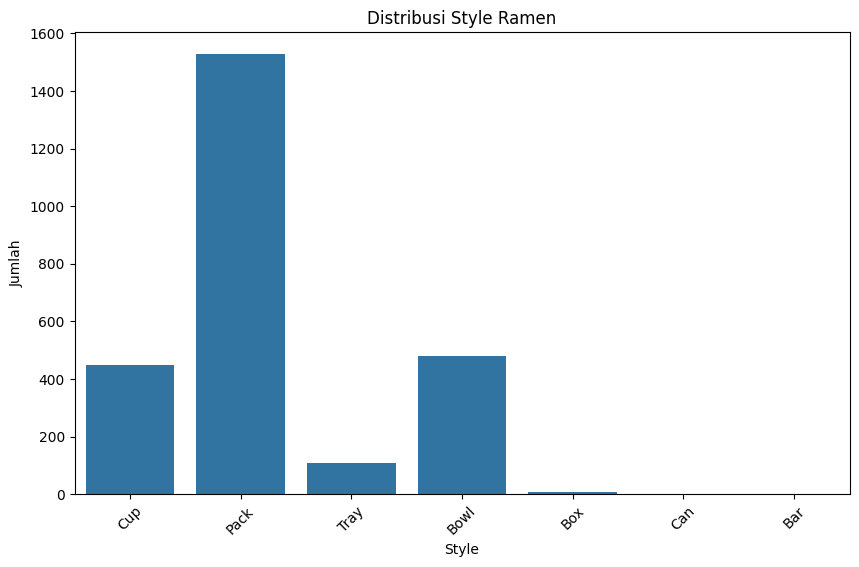

In [15]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x="Style")

plt.title("Distribusi Style Ramen")
plt.xlabel("Style")
plt.ylabel("Jumlah")
plt.xticks(rotation=45)

plt.show()

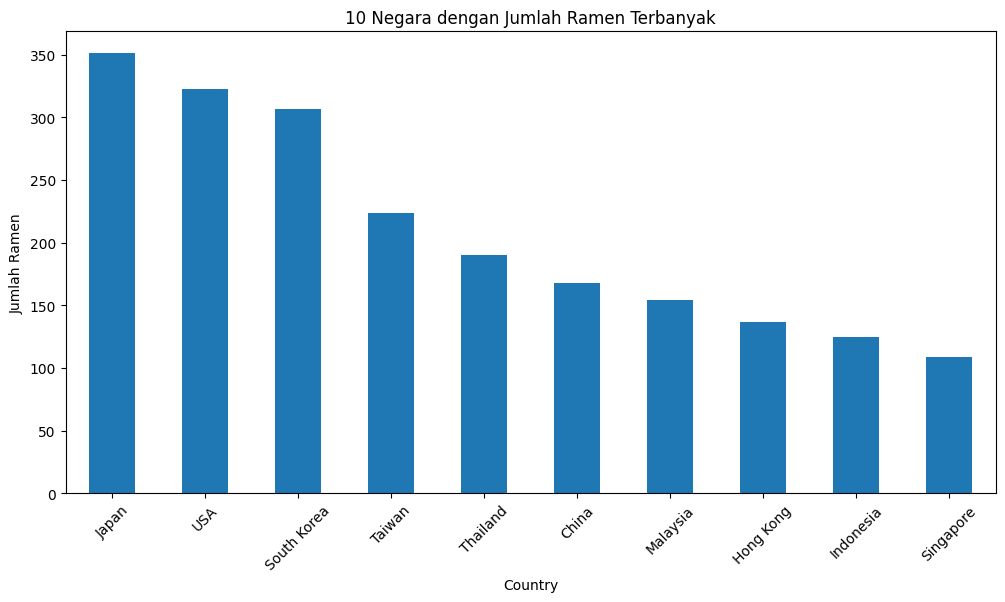

In [16]:
plt.figure(figsize=(12, 6))

df["Country"].value_counts().head(10).plot(kind="bar")

plt.title("10 Negara dengan Jumlah Ramen Terbanyak")
plt.xlabel("Country")
plt.ylabel("Jumlah Ramen")
plt.xticks(rotation=45)

plt.show()

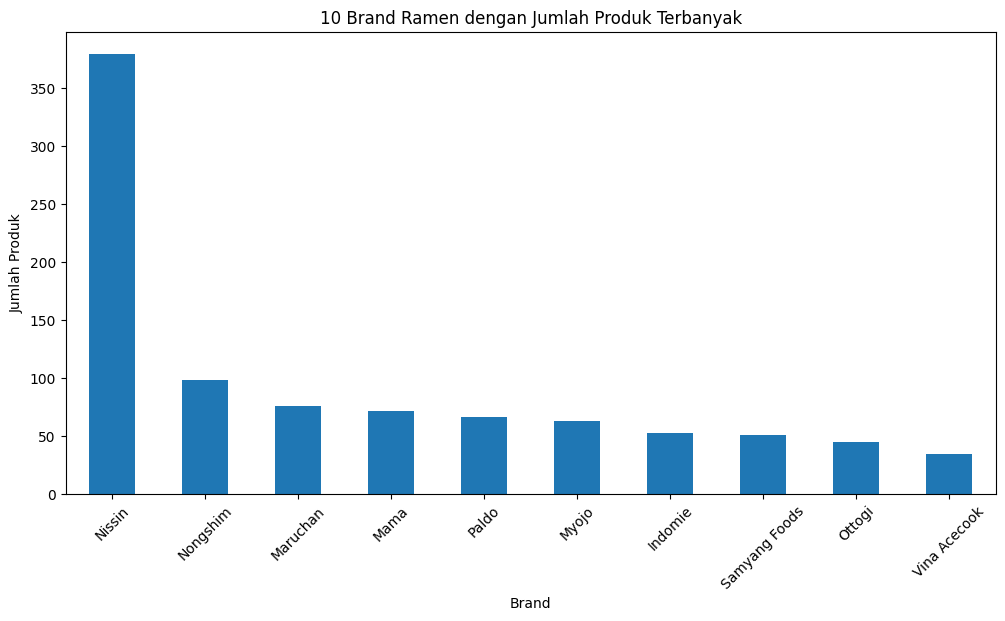

In [17]:
plt.figure(figsize=(12, 6))

df["Brand"].value_counts().head(10).plot(kind="bar")

plt.title("10 Brand Ramen dengan Jumlah Produk Terbanyak")
plt.xlabel("Brand")
plt.ylabel("Jumlah Produk")
plt.xticks(rotation=45)

plt.show()

Style
Bar     5.000000
Box     4.291667
Pack    3.698331
Bowl    3.667745
Tray    3.545139
Can     3.500000
Cup     3.497383
Name: Stars, dtype: float64


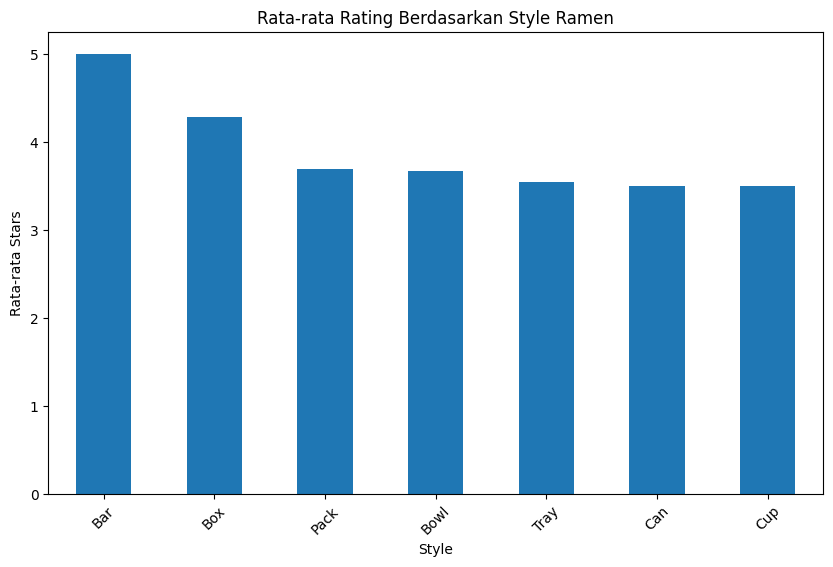

In [18]:
style_rating = df.groupby("Style")["Stars"].mean().sort_values(ascending=False)
print(style_rating)
plt.figure(figsize=(10, 6))

style_rating.plot(kind="bar")

plt.title("Rata-rata Rating Berdasarkan Style Ramen")
plt.xlabel("Style")
plt.ylabel("Rata-rata Stars")
plt.xticks(rotation=45)

plt.show()

In [19]:
category_features = ["Brand", "Variety", "Style", "Country"]
df[category_features].head()
label_encoder = LabelEncoder()

df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

df_lencoder.head()

,Brand,Variety,Style,Country,Stars
0,190,2186,4,18,3.75
1,119,1443,5,32,1.00
2,192,454,4,35,2.25
3,336,709,5,32,2.75
4,38,1951,5,16,3.75


In [20]:
features = ["Brand", "Variety", "Style", "Country"]

scaler = StandardScaler()

df_lencoder[features] = scaler.fit_transform(
    df_lencoder[features]
)
df_lencoder.head()

,Brand,Variety,Style,Country,Stars
0,0.075520,1.408997,-0.072162,-0.618216,3.75
1,-0.730447,0.352335,0.567838,0.784918,1.00
2,0.098224,-1.054178,-0.072162,1.085590,2.25
3,1.732861,-0.691528,0.567838,0.784918,2.75
4,-1.649930,1.074790,0.567838,-0.818664,3.75


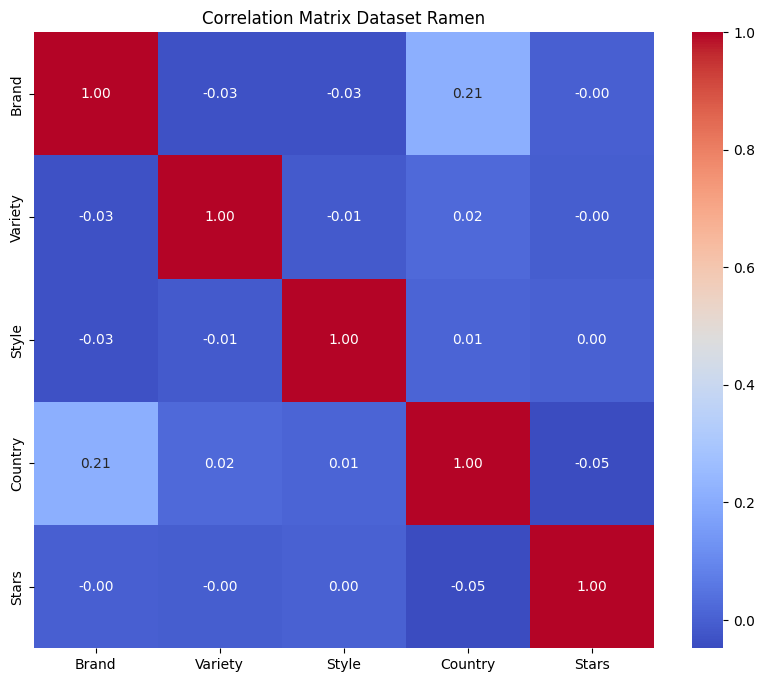

In [21]:
correlation_matrix = df_lencoder.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix Dataset Ramen")

plt.show()

In [22]:
X = df_lencoder.drop(columns=["Stars"])
y = df_lencoder["Stars"]

print("X:")
print(X.head())

print("\ny:")
print(y.head())
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

X:
      Brand   Variety     Style   Country
0  0.075520  1.408997 -0.072162 -0.618216
1 -0.730447  0.352335  0.567838  0.784918
2  0.098224 -1.054178 -0.072162  1.085590
3  1.732861 -0.691528  0.567838  0.784918
4 -1.649930  1.074790  0.567838 -0.818664

y:
0    3.75
1    1.00
2    2.25
3    2.75
4    3.75
Name: Stars, dtype: float64
Ukuran X: (2572, 4)
Ukuran y: (2572,)


In [23]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)
print("Jumlah seluruh data :", len(X))
print("Jumlah data training:", len(x_train))
print("Jumlah data testing :", len(x_test))

Jumlah seluruh data : 2572
Jumlah data training: 2057
Jumlah data testing : 515


In [24]:
lars = linear_model.Lars(
    n_nonzero_coefs=1
).fit(x_train, y_train)
pred_lars = lars.predict(x_test)

print(pred_lars[:10])

[3.608176   3.67405467 3.62755208 3.62367686 3.69730596 3.67792988
 3.62755208 3.62755208 3.61980164 3.67792988]


In [25]:
LR = LinearRegression().fit(
    x_train,
    y_train
)
pred_LR = LR.predict(x_test)

print(pred_LR[:10])

[3.61304824 3.67520278 3.63902744 3.61638698 3.69489857 3.68252076
 3.61896462 3.62802627 3.61541175 3.69056215]


In [26]:
GBR = GradientBoostingRegressor(
    random_state=184
)
GBR.fit(
    x_train,
    y_train
)
pred_GBR = GBR.predict(x_test)
print(pred_GBR[:10])

[3.33633637 3.79025614 3.39984586 3.65394324 3.70433893 4.35590629
 3.86784499 3.63840129 3.35446801 3.74938616]


In [27]:
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

print("LARS")
print("MAE :", mae_lars)
print("MSE :", mse_lars)
print("R2  :", r2_lars)

LARS
MAE : 0.7576621207384888
MSE : 1.0314114974429587
R2  : 0.0028005416988313714


In [28]:
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

print("Linear Regression")
print("MAE :", mae_LR)
print("MSE :", mse_LR)
print("R2  :", r2_LR)

Linear Regression
MAE : 0.7575519874360986
MSE : 1.0309485579145687
R2  : 0.0032481254693061956


In [29]:
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

print("Gradient Boosting Regressor")
print("MAE :", mae_GBR)
print("MSE :", mse_GBR)
print("R2  :", r2_GBR)

Gradient Boosting Regressor
MAE : 0.7099642480212626
MSE : 0.857033501879493
R2  : 0.17139439889999009


In [30]:
df_results = pd.DataFrame(
    {
        "MAE": [mae_lars, mae_LR, mae_GBR],
        "MSE": [mse_lars, mse_LR, mse_GBR],
        "R2": [r2_lars, r2_LR, r2_GBR]
    },
    index=[
        "LARS",
        "Linear Regression",
        "Gradient Boosting Regressor"
    ]
)
df_results

,MAE,MSE,R2
LARS,0.757662,1.031411,0.002801
Linear Regression,0.757552,1.030949,0.003248
Gradient Boosting Regressor,0.709964,0.857034,0.171394


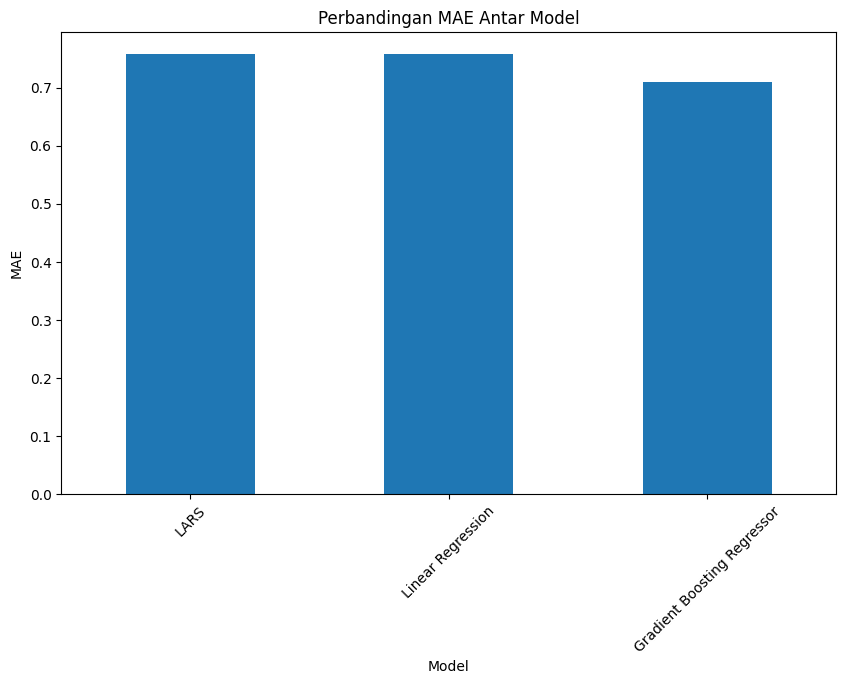

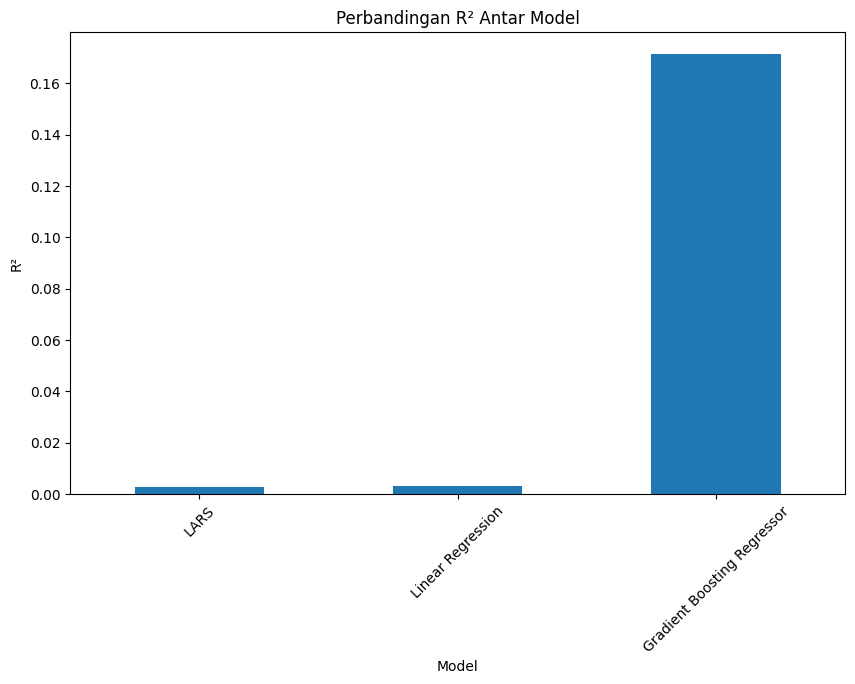

In [31]:
plt.figure(figsize=(10, 6))

df_results["MAE"].plot(kind="bar")

plt.title("Perbandingan MAE Antar Model")
plt.xlabel("Model")
plt.ylabel("MAE")
plt.xticks(rotation=45)

plt.show()
plt.figure(figsize=(10, 6))

df_results["R2"].plot(kind="bar")

plt.title("Perbandingan R² Antar Model")
plt.xlabel("Model")
plt.ylabel("R²")
plt.xticks(rotation=45)

plt.show()

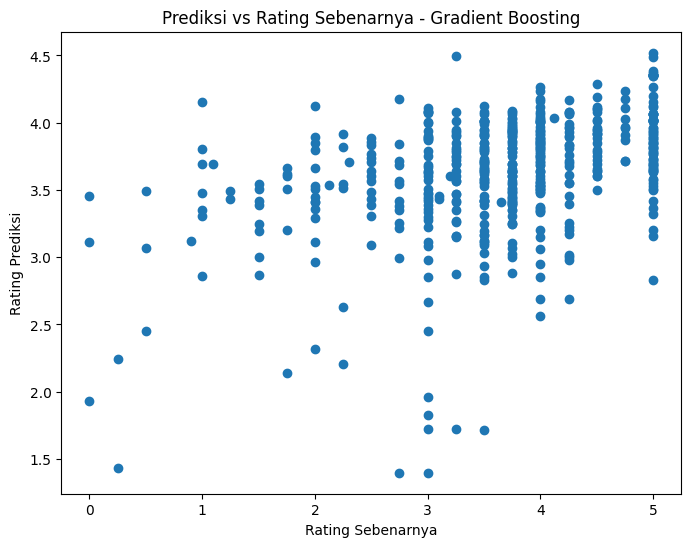

,Rating Sebenarnya,Rating Prediksi
0,4.00,3.336336
1,3.00,3.790256
2,3.75,3.399846
3,3.50,3.653943
4,2.30,3.704339
5,5.00,4.355906
6,3.00,3.867845
7,5.00,3.638401
8,2.75,3.354468
9,4.50,3.749386


In [32]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, pred_GBR)

plt.xlabel("Rating Sebenarnya")
plt.ylabel("Rating Prediksi")
plt.title("Prediksi vs Rating Sebenarnya - Gradient Boosting")

plt.show()
hasil_prediksi = pd.DataFrame({
    "Rating Sebenarnya": y_test.values,
    "Rating Prediksi": pred_GBR
})

hasil_prediksi.head(10)

In [33]:
#Cek versi pustaka yang digunakan
import sys, sklearn, joblib
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('joblib:', joblib.__version__)

#Flask diperlukan untuk menjalankan API
#Untuk menginstall klik diterminal: pip install Flask scipy

Python: 3.12.6
scikit-learn: 1.8.0
joblib: 1.5.3


In [34]:
import joblib
from sklearn.preprocessing import LabelEncoder

# Simpan model Gradient Boosting
joblib.dump(GBR, 'gbr_model.joblib')

# Membuat encoder untuk setiap fitur kategori
category_features = [
    "Brand",
    "Variety",
    "Style",
    "Country"
]

label_encoders = {}

for col in category_features:
    encoder = LabelEncoder()
    encoder.fit(df[col].astype(str))
    label_encoders[col] = encoder

# Simpan encoder dan scaler
joblib.dump(label_encoders, 'label_encoders.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model dan preprocessing berhasil disimpan.")

Model dan preprocessing berhasil disimpan.


In [35]:
import joblib

joblib_model = joblib.load('gbr_model.joblib')
loaded_scaler = joblib.load('scaler.pkl')
loaded_encoders = joblib.load('label_encoders.pkl')

print("Model dan preprocessing berhasil dimuat.")

Model dan preprocessing berhasil dimuat.


In [36]:
# CELL 3 — TEST PREDIKSI

import pandas as pd

data_baru = pd.DataFrame({
    "Brand": ["Nissin"],
    "Variety": ["Cup Noodles Chicken"],
    "Style": ["Cup"],
    "Country": ["USA"]
})

category_features = [
    "Brand",
    "Variety",
    "Style",
    "Country"
]

# Encoding
for col in category_features:
    data_baru[col] = loaded_encoders[col].transform(
        data_baru[col].astype(str)
    )

# Scaling
data_scaled = loaded_scaler.transform(data_baru)

# Prediksi
prediction = joblib_model.predict(data_scaled)

print("Prediksi Stars:", prediction[0])

Prediksi Stars: 3.6301063627264267


C:\Users\Thoriq\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GradientBoostingRegressor was fitted with feature names
  warnings.warn(


In [37]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Prediksi data test
y_pred = GBR.predict(x_test)

# Menghitung metrik
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== MODEL MONITORING =====")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)

===== MODEL MONITORING =====
MAE  : 0.7099642480212626
MSE  : 0.857033501879493
RMSE : 0.9257610392965849
R²   : 0.17139439889999009
